# MBAS exploratory data analysis

Generated by `notebooks/make_eda.py`. Synthetic data is labelled as such; public datasets are used for pre-training only.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ml.common.config import PROCESSED, PUBLIC, LABELS, SYNTHETIC, abspath
plt.rcParams.update({'figure.figsize': (10, 3.2), 'axes.grid': True, 'grid.alpha': .3})
def have(p): return Path(p).exists()

## 1. Window labels (5 s, 2.5 s hop)

recorded : no labelled windows yet


synthetic 46234 windows; {'on_screen': 31000, 'off_screen': 15234} {'engaged': 21245, 'neutral': 20647, 'disengaged': 4342}


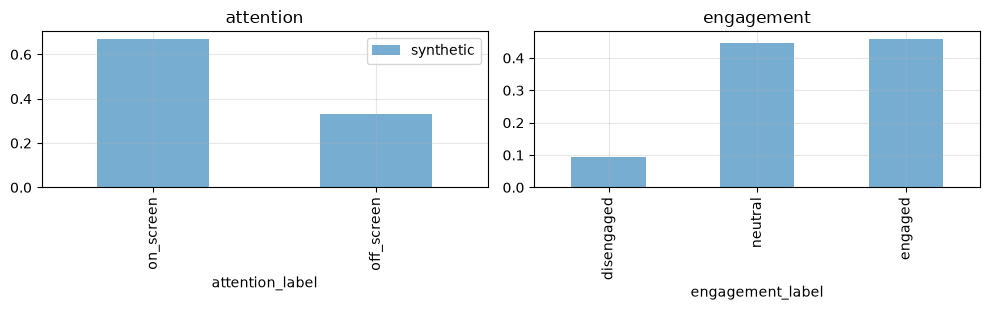

In [2]:
fig, ax = plt.subplots(1, 2)
for src, m in (('recorded', 'o'), ('synthetic', 's')):
    p = PROCESSED / 'windows' / f'windows_{src}.parquet'
    if not have(p): continue
    w = pd.read_parquet(p)
    if w.attention_label.notna().sum() == 0: print(src, ': no labelled windows yet'); continue
    w.attention_label.value_counts(normalize=True).plot.bar(ax=ax[0], alpha=.6, label=src)
    w.engagement_label.value_counts(normalize=True).reindex(['disengaged','neutral','engaged']).plot.bar(ax=ax[1], alpha=.6, label=src)
    print(src, len(w), 'windows;', w.attention_label.value_counts().to_dict(), w.engagement_label.value_counts().to_dict())
ax[0].set_title('attention'); ax[1].set_title('engagement'); ax[0].legend(); plt.tight_layout(); plt.show()

## 2. Answer labels

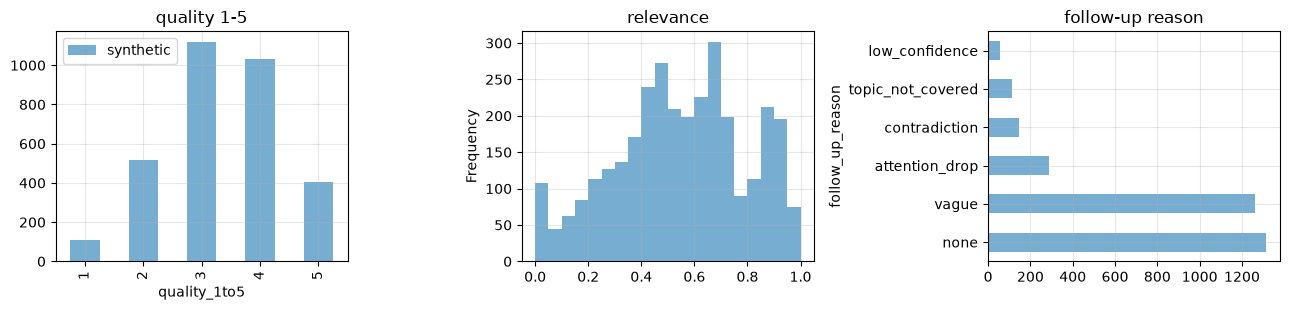

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for src in ('recorded', 'synthetic'):
    p = LABELS / src / 'answers.parquet'
    if not have(p): continue
    a = pd.read_parquet(p)
    if not len(a): print(src, ': no labelled answers yet'); continue
    a.quality_1to5.value_counts().sort_index().plot.bar(ax=ax[0], alpha=.6, label=src)
    a.relevance.plot.hist(ax=ax[1], bins=20, alpha=.6, label=src)
    a.follow_up_reason.value_counts().plot.barh(ax=ax[2], alpha=.6, label=src)
ax[0].set_title('quality 1-5'); ax[1].set_title('relevance'); ax[2].set_title('follow-up reason')
ax[0].legend(); plt.tight_layout(); plt.show()

## 3. Durations

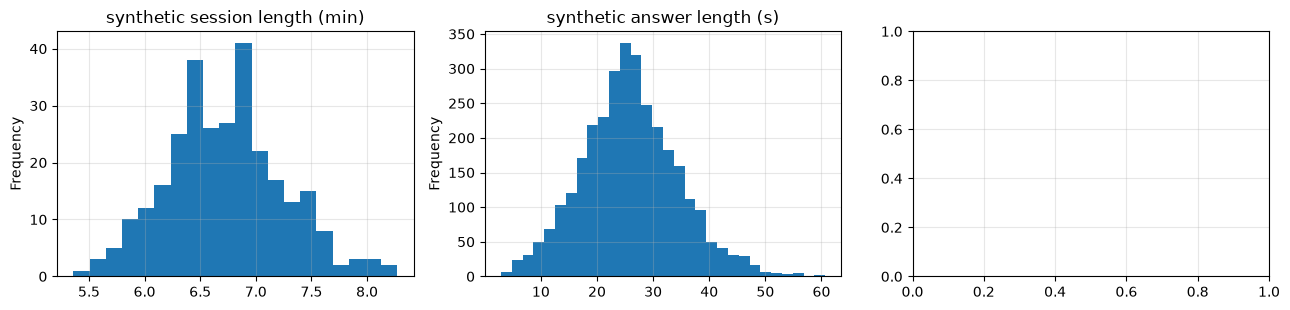

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
if have(SYNTHETIC / 'interview' / 'sessions.csv'):
    s = pd.read_csv(SYNTHETIC / 'interview' / 'sessions.csv'); (s.duration_s / 60).plot.hist(ax=ax[0], bins=20)
    ax[0].set_title('synthetic session length (min)')
    an = pd.read_csv(SYNTHETIC / 'interview' / 'answers.csv'); an.answer_duration_s.plot.hist(ax=ax[1], bins=30)
    ax[1].set_title('synthetic answer length (s)')
if have(PUBLIC / 'librispeech' / 'manifest.parquet'):
    m = pd.read_parquet(PUBLIC / 'librispeech' / 'manifest.parquet', columns=['duration_s', 'subset'])
    m.duration_s.plot.hist(ax=ax[2], bins=40); ax[2].set_title(f'LibriSpeech utterances (s), {m.duration_s.sum()/3600:.0f} h')
plt.tight_layout(); plt.show()

## 4. Public datasets

In [5]:
rows = []
for p in sorted(PUBLIC.glob('*/info.json')):
    i = json.loads(p.read_text()); rows.append({k: i.get(k) for k in ('title', 'n_items', 'n_subjects', 'hours', 'used_for')})
pd.DataFrame(rows)

,title,n_items,n_subjects,hours,used_for
0,AMI Meeting Corpus,682,190,391.85,"meeting mode: talk balance, engagement (Stage 8)"
1,WIDER FACE,16106,61,NaN,face detector (Stage 4)


## 5. Sample frames

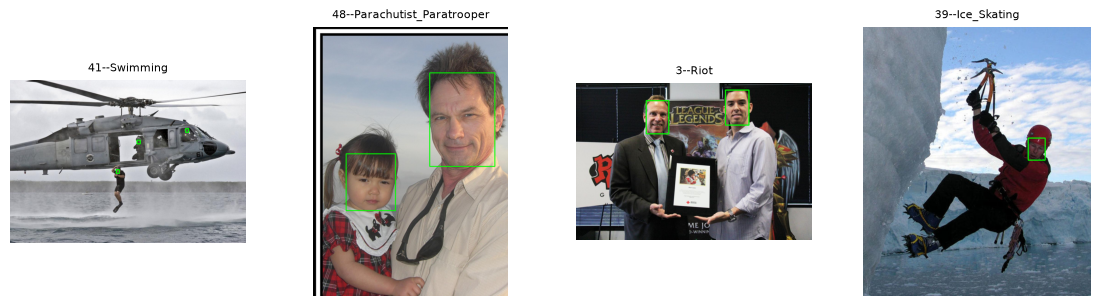

In [6]:
import cv2
if have(PUBLIC / 'wider_face' / 'manifest.parquet'):
    m = pd.read_parquet(PUBLIC / 'wider_face' / 'manifest.parquet')
    m = m[(m.n_valid_faces.between(1, 4))].sample(4, random_state=1)
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
    for a, r in zip(ax, m.itertuples()):
        img = cv2.cvtColor(cv2.imread(str(abspath(r.path))), cv2.COLOR_BGR2RGB)
        for b in json.loads(r.boxes):
            if b[7] == 0: cv2.rectangle(img, (b[0], b[1]), (b[0]+b[2], b[1]+b[3]), (0, 255, 0), 3)
        a.imshow(img); a.axis('off'); a.set_title(r.event, fontsize=8)
    plt.show()
if have(PUBLIC / 'mpiigaze'):
    zs = sorted((PUBLIC / 'mpiigaze').glob('p*.npz'))
    if zs:
        z = np.load(zs[0]); fig, ax = plt.subplots(1, 6, figsize=(14, 2))
        for k, a in enumerate(ax):
            i = k * 500; a.imshow(z['left_image'][i], cmap='gray'); a.axis('off')
            a.set_title(f"pitch {np.degrees(z['left_gaze'][i,0]):.0f} yaw {np.degrees(z['left_gaze'][i,1]):.0f}", fontsize=8)
        plt.show()

## 6. Spectrograms (80-band log-mel, 25 ms / 10 ms)

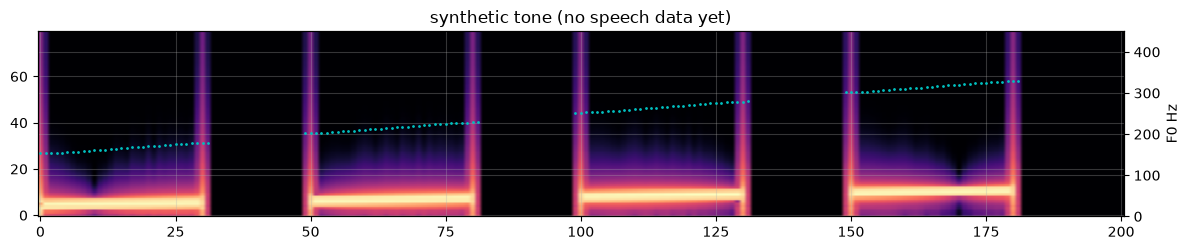

In [7]:
from ml.common.audio_features import load_audio, log_mel, pitch_yin, SR
clips = []
if have(PUBLIC / 'librispeech' / 'manifest.parquet'):
    m = pd.read_parquet(PUBLIC / 'librispeech' / 'manifest.parquet'); clips.append(('LibriSpeech ' + m.item_id.iloc[0], abspath(m.path.iloc[0])))
if have(PUBLIC / 'sep28k' / 'manifest.parquet'):
    m = pd.read_parquet(PUBLIC / 'sep28k' / 'manifest.parquet'); r = m[m.filler == 1].iloc[0]; clips.append(('SEP-28k filler ' + r.item_id, abspath(r.path)))
if not clips:
    t = np.arange(2 * SR) / SR; x = (np.sin(2 * np.pi * (150 + 50 * t) * t) * (t % .5 < .3)).astype('float32')
    clips.append(('synthetic tone (no speech data yet)', x))
fig, ax = plt.subplots(len(clips), 1, figsize=(12, 2.6 * len(clips)), squeeze=False)
for a, (name, src) in zip(ax[:, 0], clips):
    x = src if isinstance(src, np.ndarray) else load_audio(src)
    a.imshow(log_mel(x).numpy(), origin='lower', aspect='auto', cmap='magma'); a.set_title(name)
    f0 = pitch_yin(x); a2 = a.twinx(); a2.plot(f0, 'c.', ms=2); a2.set_ylim(0, 450); a2.set_ylabel('F0 Hz')
plt.tight_layout(); plt.show()